# A 2D mesher, from parameters to finite-volume faces

Pipeline (one section per step):

| Step | What | Ours or library |
|---|---|---|
| 1 | Parameterised geometry: vertices as functions of $L_1, L_2, H_1, H_2$ | ours |
| 2 | Topology: oriented `Line`s joined into a closed CCW `CurveLoop` | ours |
| 3 | Sizing field $h(x, y)$ with an attractor at the re-entrant corner | ours |
| 4 | 1D boundary seeding: nodes spaced by $h$ along each curve | ours |
| 5a | 2D triangulation **by hand**: Delaunay connectivity (scipy) + our Ruppert-style refinement loop | ours + `scipy.spatial.Delaunay` |
| 5b | 2D triangulation **by gmsh**: same geometry, same $h$ | gmsh |
| 6 | Finite-volume topology: faces, owner/neighbour, $\mathbf{S}_f$ | ours |
| 7 | Checks: closure, areas, divergence theorem, realised vs requested size | ours |

Domain: a **sudden expansion** (backward-facing step). Fluid enters a channel of height
$H_1$ on the left, the floor drops at $x = L_1$, and the channel continues with height $H_2$.

```
  p4 ┌──────────────────────────────────────────┐ p3
     │                                          │
inlet│  H1                                      │ outlet   H2
  p5 └──────────┐ p6                            │
                │  step                         │
             p1 └───────────────────────────────┘ p2
     |<-- L1 -->|<------------- L2 ------------>|
```

In [1]:
from dataclasses import dataclass

import gmsh
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.path import Path
from scipy.spatial import Delaunay, cKDTree

## Step 1 — Parameterised geometry

Every coordinate is a formula in the parameters, never a typed-in number. Change `PARAMS`
and re-run the notebook: the whole pipeline follows.

In [2]:
PARAMS = dict(
    L1=1.0,  # inlet channel length (before the step)
    L2=3.0,  # downstream channel length (after the step)
    H1=0.5,  # inlet channel height
    H2=1.0,  # downstream channel height; step height is H2 - H1
)


@dataclass(frozen=True, eq=False)  # eq=False: two Points are "the same" only if they are the same object
class Point:
    name: str
    x: float
    y: float

    @property
    def xy(self):
        return np.array([self.x, self.y])


def make_vertices(L1, L2, H1, H2):
    """Corner points p1..p6 of the sudden expansion, listed counter-clockwise."""
    if not (L1 > 0 and L2 > 0 and 0 < H1 < H2):
        raise ValueError("need L1, L2 > 0 and 0 < H1 < H2")
    s = H2 - H1  # step height
    return [
        Point("p1", L1,      0.0),  # foot of the step
        Point("p2", L1 + L2, 0.0),  # bottom of the outlet
        Point("p3", L1 + L2, H2),   # top of the outlet
        Point("p4", 0.0,     H2),   # top of the inlet
        Point("p5", 0.0,     s),    # bottom of the inlet
        Point("p6", L1,      s),    # lip of the step: the re-entrant (270 deg) corner
    ]


p1, p2, p3, p4, p5, p6 = vertices = make_vertices(**PARAMS)
for p in vertices:
    print(f"{p.name} = ({p.x:.3f}, {p.y:.3f})")

p1 = (1.000, 0.000)
p2 = (4.000, 0.000)
p3 = (4.000, 1.000)
p4 = (0.000, 1.000)
p5 = (0.000, 0.500)
p6 = (1.000, 0.500)


## Step 2 — Topological connectivity

*"Geometrical coincidence alone is insufficient."* Two lines that merely end at the same
coordinates are not connected; they are connected when they share the **same `Point`
object**. That is why `Point` uses `eq=False` and `CurveLoop` checks `a.end is b.start`
(identity), not `==` on coordinates.

Each `Line` is the oriented segment $C_i(t) = (1 - t)\,p_i + t\,p_{i+1}$, $t \in [0, 1]$, and
carries the name of the boundary **patch** it belongs to; the FVM solver needs that later.

The outer loop must be counter-clockwise: then the domain is always on the **left** of each
curve, and "right of the direction of travel" is the outward normal. The shoelace formula
gives the signed area, positive iff CCW.

loop signed area = 3.500000  (expected L1*H1 + L2*H2 = 3.500000)


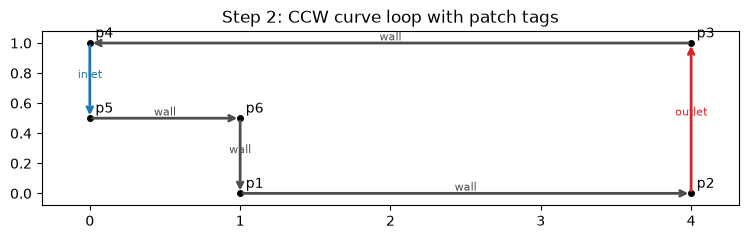

In [3]:
@dataclass(frozen=True, eq=False)
class Line:
    start: Point
    end: Point
    patch: str | None  # boundary condition group: "inlet", "outlet", "wall"; None = interior cut between zones

    def __call__(self, t):
        """C(t) = (1 - t) start + t end, vectorised: t of shape (n,) -> points of shape (n, 2)."""
        t = np.asarray(t, float)[..., None]
        return (1 - t) * self.start.xy + t * self.end.xy

    @property
    def length(self):
        return float(np.linalg.norm(self.end.xy - self.start.xy))

    @property
    def area_term(self):
        """This curve's share of the loop's signed area, 1/2 * integral of (x dy - y dx) (Green's theorem)."""
        return 0.5 * float(self.start.x * self.end.y - self.end.x * self.start.y)

    def __neg__(self):
        return Reversed(self)


class Reversed:
    """The same Line walked backwards (`-line`). It wraps the original object instead of copying it,
    so two zones that share a line really share it; gmsh writes this as a negative curve tag."""

    def __init__(self, line):
        self.line = line

    start = property(lambda self: self.line.end)
    end = property(lambda self: self.line.start)
    patch = property(lambda self: self.line.patch)
    length = property(lambda self: self.line.length)
    area_term = property(lambda self: -self.line.area_term)

    def __call__(self, t):
        return self.line(1 - np.asarray(t, float))


@dataclass(frozen=True, eq=False)
class Arc:
    """Circular arc from start to end around centre, C(t) = c + r (cos th(t), sin th(t)), th linear in t.
    gmsh only accepts arcs spanning less than 180 deg, so a full circle is built from several arcs."""
    start: Point
    end: Point
    centre: Point
    patch: str | None
    clockwise: bool = False

    @property
    def radius(self):
        return float(np.linalg.norm(self.start.xy - self.centre.xy))

    def _angles(self):
        """Start angle and signed sweep (negative = clockwise)."""
        a0 = np.arctan2(self.start.y - self.centre.y, self.start.x - self.centre.x)
        a1 = np.arctan2(self.end.y - self.centre.y, self.end.x - self.centre.x)
        sweep = (a1 - a0) % (2 * np.pi)
        return a0, (sweep - 2 * np.pi if self.clockwise else sweep)

    def __call__(self, t):
        a0, sweep = self._angles()
        th = a0 + sweep * np.asarray(t, float)[..., None]   # constant speed, so Step 4 seeding works as is
        return self.centre.xy + self.radius * np.concatenate([np.cos(th), np.sin(th)], axis=-1)

    @property
    def length(self):
        return abs(self._angles()[1]) * self.radius

    @property
    def area_term(self):
        """1/2 * integral of (x dy - y dx) along the arc = 1/2 [cx (y1 - y0) - cy (x1 - x0) + r^2 sweep]."""
        c, (x0, y0), (x1, y1) = self.centre, self.start.xy, self.end.xy
        return 0.5 * float(c.x * (y1 - y0) - c.y * (x1 - x0) + self.radius ** 2 * self._angles()[1])


def _cross(o, a, b):
    """z-component of (a - o) x (b - o): > 0 if o -> a -> b turns left."""
    return (a[0] - o[0]) * (b[1] - o[1]) - (a[1] - o[1]) * (b[0] - o[0])


def _segments_cross(a, b, c, d):
    """True if segments ab and cd properly intersect (cross at an interior point)."""
    return (_cross(a, b, c) * _cross(a, b, d) < 0) and (_cross(c, d, a) * _cross(c, d, b) < 0)


class CurveLoop:
    """A closed, non-self-intersecting chain of curves: counter-clockwise for an outer boundary,
    clockwise for a hole. Either way the domain is on the left of every curve."""

    def __init__(self, curves, hole=False):
        n = len(curves)
        # Closure by identity: curve i must end on the very Point object curve i+1 starts at.
        for i in range(n):
            a, b = curves[i], curves[(i + 1) % n]
            if a.end is not b.start:
                raise ValueError(f"curve {i} ends at {a.end.name}, curve {i+1} starts at {b.start.name}")
        # No two non-adjacent curves may cross. ponytail: O(n^2) pair scan, fine for a handful of curves.
        for i in range(n):
            for j in range(i + 2, n):
                if i == 0 and j == n - 1:
                    continue  # first and last curve are neighbours through the closing vertex
                ci, cj = curves[i], curves[j]
                if _segments_cross(ci.start.xy, ci.end.xy, cj.start.xy, cj.end.xy):
                    raise ValueError(f"curves {i} and {j} intersect")
        self.curves = curves
        self.hole = hole
        if (self.signed_area() > 0) == hole:
            raise ValueError("outer boundaries must be CCW and holes CW (or the loop is degenerate)")

    @property
    def vertices(self):
        return [c.start for c in self.curves]

    def signed_area(self):
        """Green's theorem, 1/2 * loop integral of (x dy - y dx), summed curve by curve. Positive <=> CCW.
        For straight lines this is the shoelace formula; for arcs it is still exact."""
        return sum(c.area_term for c in self.curves)

    def contains(self, xy):
        """Point-in-region test for an (n, 2) array: inside the loop (strict interior; boundary is ambiguous).
        Curves are sampled, so arcs are approximated by 32 chords each; straight lines are exact."""
        poly = np.vstack([c(np.linspace(0, 1, 33))[:-1] for c in self.curves])
        return Path(poly).contains_points(xy)


loop = CurveLoop([
    Line(p1, p2, "wall"),    # bottom wall downstream of the step
    Line(p2, p3, "outlet"),
    Line(p3, p4, "wall"),    # top wall
    Line(p4, p5, "inlet"),
    Line(p5, p6, "wall"),    # floor of the inlet channel
    Line(p6, p1, "wall"),    # vertical face of the step
])

exact_area = PARAMS["L1"] * PARAMS["H1"] + PARAMS["L2"] * PARAMS["H2"]
print(f"loop signed area = {loop.signed_area():.6f}  (expected L1*H1 + L2*H2 = {exact_area:.6f})")

# Picture: arrows show the traversal direction, colours show the patches.
PATCH_COLOURS = {"inlet": "tab:blue", "outlet": "tab:red", "wall": "0.3"}
fig, ax = plt.subplots(figsize=(9, 3))
for c in loop.curves:
    a, b = c.start.xy, c.end.xy
    ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="->", color=PATCH_COLOURS[c.patch], lw=2))
    ax.text(*(0.5 * (a + b)), c.patch, color=PATCH_COLOURS[c.patch], ha="center", va="bottom", fontsize=8)
for p in loop.vertices:
    ax.plot(*p.xy, "ko", ms=4)
    ax.annotate(p.name, p.xy, xytext=(4, 4), textcoords="offset points")
ax.set_aspect("equal"); ax.set_title("Step 2: CCW curve loop with patch tags"); ax.margins(0.08)
plt.show()

## Step 3 — Mesh sizing field

$h(x, y)$ is the edge length we *ask for* at each point. The flow separates at the lip of the
step $p_6$, so that is where we want small cells. With $d$ = distance to the attractor:

$$
s = \operatorname{clip}\!\left(\frac{d - d_{\min}}{d_{\max} - d_{\min}}, 0, 1\right),\qquad
h = h_{\min} + (h_{\max} - h_{\min})\,s^2(3 - 2s)
$$

$s^2(3 - 2s)$ is the "smoothstep" polynomial: 0 to 1 with zero slope at both ends, so $h$
has no kinks. The steepest gradient is $1.5\,(h_{\max}-h_{\min})/(d_{\max}-d_{\min})$; keep
it well below 1 or neighbouring cells change size too abruptly.

h at p6 = 0.010, h at outlet corner p3 = 0.100


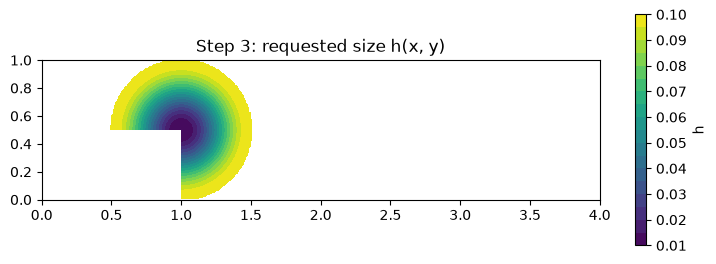

In [4]:
def make_size_field(attractor, hmin=0.01, hmax=0.1, dmin=0.02, dmax=0.5):
    """h(x, y): hmin within dmin of the attractor, smoothstep up to hmax beyond dmax. Vectorised.
    `attractor` is a Point, or any function (x, y) -> distance to whatever should attract small cells."""
    if isinstance(attractor, Point):
        p = attractor
        attractor = lambda x, y: np.hypot(np.asarray(x, float) - p.x, np.asarray(y, float) - p.y)

    def h(x, y):
        d = attractor(x, y)
        s = np.clip((d - dmin) / (dmax - dmin), 0.0, 1.0)
        return hmin + (hmax - hmin) * s * s * (3 - 2 * s)
        

    return h


h = make_size_field(p6)
print(f"h at p6 = {h(p6.x, p6.y):.3f}, h at outlet corner p3 = {h(p3.x, p3.y):.3f}")

# Picture: h over a background grid, masked to the domain.
X, Y = np.meshgrid(np.linspace(0, PARAMS["L1"] + PARAMS["L2"], 400), np.linspace(0, PARAMS["H2"], 120))
H = np.ma.masked_where(~loop.contains(np.c_[X.ravel(), Y.ravel()]).reshape(X.shape), h(X, Y))
fig, ax = plt.subplots(figsize=(9, 3))
cs = ax.contourf(X, Y, H, levels=20, cmap="viridis")
fig.colorbar(cs, ax=ax, label="h")
ax.set_aspect("equal"); ax.set_title("Step 3: requested size h(x, y)")
plt.show()

## Step 4 — Boundary discretisation (1D meshing)

Walk each curve from $t = 0$ to $t = 1$. The number of cells "owed" by the stretch $[0, t]$ is

$$ N(t) = \int_0^t \frac{\lVert C'(\tau)\rVert}{h(C(\tau))}\, d\tau = \int_0^t \frac{L}{h(C(\tau))}\, d\tau $$

(arc length divided by the local cell size). Round $N(1)$ to an integer $n$, rescale so $N(1) = n$
exactly, and put node $k$ where $N(t_k) = k$. Where $h$ is small $N$ climbs fast, so nodes bunch.

Curve end points are the shared `Point`s from Step 2, so neighbouring curves reuse the same
node: the discrete loop is watertight by construction.

124 boundary nodes, 124 segments
segment length / h(midpoint): min 0.99, max 1.00   (want ~1)


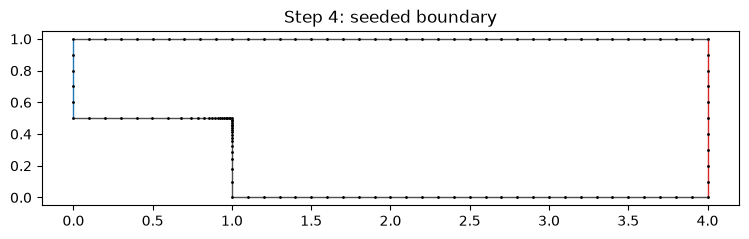

In [5]:
def seed_curve(curve, h, samples_per_hmin=20):
    """Parameters 0 = t_0 < ... < t_n = 1 with spacing following h along the curve."""
    hmin = float(np.min(h(*curve(np.linspace(0, 1, 1001)).T)))
    m = max(1001, int(samples_per_hmin * curve.length / hmin))  # fine enough to resolve h
    t = np.linspace(0.0, 1.0, m)
    
    f = curve.length / h(*curve(t).T)                                   # integrand L / h(C(t))
    N = np.concatenate([[0.0], np.cumsum(0.5 * (f[1:] + f[:-1]) * np.diff(t))])  # trapezoid rule
    n = max(1, int(round(N[-1])))
    return np.interp(np.arange(n + 1), N * (n / N[-1]), t)               # invert N(t) = k


def seed_loop(loop, h):
    """Discretise every curve of the loop.

    Returns
      nodes  (Nb, 2)  boundary node coordinates; the first len(loop.curves) are the vertices
      segs   (M, 2)   node index pairs, in loop (CCW) order
      patch  (M,)     patch name of each segment
    """
    nodes = [p.xy for p in loop.vertices]
    node_of = {p: i for i, p in enumerate(loop.vertices)}  # Point object -> node index
    segs, patch = [], []
    for c in loop.curves:
        t = seed_curve(c, h)
        inner = list(range(len(nodes), len(nodes) + len(t) - 2))
        nodes.extend(c(t[1:-1]))
        ids = [node_of[c.start]] + inner + [node_of[c.end]]
        segs.extend(zip(ids[:-1], ids[1:]))
        patch.extend([c.patch] * (len(ids) - 1))
    return np.array(nodes), np.array(segs), np.array(patch)


bnodes, bsegs, bpatch = seed_loop(loop, h)
seg_len = np.linalg.norm(bnodes[bsegs[:, 1]] - bnodes[bsegs[:, 0]], axis=1)
seg_mid = 0.5 * (bnodes[bsegs[:, 0]] + bnodes[bsegs[:, 1]])
print(f"{len(bnodes)} boundary nodes, {len(bsegs)} segments")
print(f"segment length / h(midpoint): min {np.min(seg_len / h(*seg_mid.T)):.2f}, "
      f"max {np.max(seg_len / h(*seg_mid.T)):.2f}   (want ~1)")

fig, ax = plt.subplots(figsize=(9, 3))
for name, col in PATCH_COLOURS.items():
    for a, b in bsegs[bpatch == name]:
        ax.plot(*bnodes[[a, b]].T, "-", color=col, lw=1)
ax.plot(*bnodes.T, "k.", ms=2)
ax.set_aspect("equal"); ax.set_title("Step 4: seeded boundary")
plt.show()

## Step 5a — Triangulation by hand (Delaunay refinement)

`scipy.spatial.Delaunay` gives us the Delaunay connectivity of a point set (no circumcircle
contains another point). Everything else is ours, following Ruppert's algorithm:

1. **Triangulate** all current nodes. Delaunay meshes the *convex hull*, so it also fills the
   notch under the step; keep only triangles whose centroid is inside the loop.
2. **Recover the boundary.** A boundary segment whose *diametral circle* (the circle with the
   segment as diameter) contains no other node is guaranteed to be a Delaunay edge. If some node
   *encroaches* (lies inside it), split the segment at its midpoint and go back to 1.
3. **Refine.** A triangle is *bad* if
   - too big: circumradius $R > \tau\, h/\sqrt3$ (an equilateral triangle of side $h$ has $R = h/\sqrt3$), or
   - too skinny: $R / \ell_{\min} > \sqrt2$, i.e. smallest angle below $\approx 20.7^\circ$.

   Why the tolerance $\tau$ (`size_tol`)? Refinement only *stops* once every triangle is under the
   limit, so with $\tau = 1$ the limit acts as a ceiling and cells come out ~30% smaller than $h$.
   $\tau = 1.3$ puts the median $h_{\text{mesh}}/h$ near 0.9 (gmsh aims for $h$ on average instead).

   For each bad triangle, the candidate new node is its **circumcenter** (the point farthest
   from every existing node, so it splits the triangle evenly). If the candidate would encroach
   a boundary segment, split that segment instead; this is what stops nodes escaping the domain.
4. Repeat until nothing is encroached and nothing is bad.

scipy re-triangulates from scratch every round. ponytail: O(rounds x N log N); an incremental
Bowyer–Watson insert is the upgrade if meshes get large.

In [6]:
def circumcircles(P, tris):
    """Circumcenters (T, 2) and circumradii (T,) of triangles given as node-index rows."""
    a, b, c = P[tris[:, 0]], P[tris[:, 1]], P[tris[:, 2]]
    d = 2 * (a[:, 0] * (b[:, 1] - c[:, 1]) + b[:, 0] * (c[:, 1] - a[:, 1]) + c[:, 0] * (a[:, 1] - b[:, 1]))
    a2, b2, c2 = (a * a).sum(1), (b * b).sum(1), (c * c).sum(1)
    ux = (a2 * (b[:, 1] - c[:, 1]) + b2 * (c[:, 1] - a[:, 1]) + c2 * (a[:, 1] - b[:, 1])) / d
    uy = (a2 * (c[:, 0] - b[:, 0]) + b2 * (a[:, 0] - c[:, 0]) + c2 * (b[:, 0] - a[:, 0])) / d
    cc = np.c_[ux, uy]
    return cc, np.linalg.norm(a - cc, axis=1)


def signed_areas(P, cells):
    """Shoelace area of every cell (any number of nodes per row); > 0 means CCW."""
    x, y = P[cells, 0], P[cells, 1]
    return 0.5 * (x * np.roll(y, -1, axis=1) - np.roll(x, -1, axis=1) * y).sum(axis=1)


def make_ccw(P, cells):
    """Reverse the node order of every clockwise cell, so all cells are CCW."""
    cells = cells.copy()
    cw = signed_areas(P, cells) < 0
    cells[cw] = cells[cw][:, ::-1]
    return cells


def triangulate_inside(P, loop):
    """Delaunay of all nodes, keeping only triangles inside the loop, oriented CCW."""
    dt = Delaunay(P)
    assert len(dt.coplanar) == 0, "qhull dropped some nodes"
    tris = dt.simplices
    return make_ccw(P, tris[loop.contains(P[tris].mean(axis=1))])


def encroached_by_nodes(P, segs):
    """Mask of segments whose diametral circle strictly contains some node."""
    mid = 0.5 * (P[segs[:, 0]] + P[segs[:, 1]])
    r = 0.5 * np.linalg.norm(P[segs[:, 1]] - P[segs[:, 0]], axis=1)
    # Shrink r a hair so a segment's own endpoints (at distance exactly r) don't count.
    return cKDTree(P).query_ball_point(mid, r * (1 - 1e-9), return_length=True) > 0


def split_segments(P, segs, patch, which):
    """Insert the midpoint of every segment in `which` (bool mask); children keep the patch."""
    a, b = segs[which, 0], segs[which, 1]
    m = np.arange(len(P), len(P) + len(a))
    P = np.vstack([P, 0.5 * (P[a] + P[b])])
    segs = np.vstack([segs[~which], np.c_[a, m], np.c_[m, b]])
    patch = np.concatenate([patch[~which], patch[which], patch[which]])
    return P, segs, patch


def refine(loop, h, bnodes, bsegs, bpatch, size_tol=1.0, quality=np.sqrt(2), max_rounds=500, history=None):
    P, segs, patch = bnodes.copy(), bsegs.copy(), bpatch.copy()
    for rnd in range(max_rounds):
        tris = triangulate_inside(P, loop)

        # (2) boundary recovery: no node may sit inside a segment's diametral circle.
        enc = encroached_by_nodes(P, segs)
        if enc.any():
            P, segs, patch = split_segments(P, segs, patch, enc)
            continue

        # (3) find bad triangles.
        cc, R = circumcircles(P, tris)
        e = P[tris[:, [1, 2, 0]]] - P[tris]                 # the 3 edge vectors of each triangle
        lmin = np.linalg.norm(e, axis=2).min(axis=1)
        h_here = h(*P[tris].mean(axis=1).T)
        bad = (R * np.sqrt(3) > size_tol * h_here) | (R / lmin > quality)
        if history is not None:
            history.append(dict(round=rnd, nodes=len(P), tris=len(tris), bad=int(bad.sum())))
        if not bad.any():
            return P, tris, segs, patch

        # Largest bad triangles first: their circumcenters do the most good.
        order = np.argsort(-R[bad])
        cand, cand_R = cc[bad][order], R[bad][order]

        # Would the candidate encroach a boundary segment? -> split that segment instead.
        mid = 0.5 * (P[segs[:, 0]] + P[segs[:, 1]])
        r = 0.5 * np.linalg.norm(P[segs[:, 1]] - P[segs[:, 0]], axis=1)
        hits = np.linalg.norm(cand[:, None, :] - mid[None, :, :], axis=2) < r[None, :]   # (K, M)
        to_split = hits.any(axis=0)
        free = cand[~hits.any(axis=1)]
        free_R = cand_R[~hits.any(axis=1)]
        assert loop.contains(free).all(), "circumcenter left the domain without encroaching a segment"

        # Many insertions per round: drop candidates that land close to one already accepted
        # this round, or two neighbouring bad triangles would both drop a node in nearly one spot.
        # ponytail: greedy O(K^2) scan; a KD-tree is the upgrade if K gets large.
        accepted = []
        for c, Rc in zip(free, free_R):
            if not accepted or np.min(np.linalg.norm(np.array(accepted) - c, axis=1)) > 0.5 * Rc:
                accepted.append(c)
        if accepted:
            P = np.vstack([P, accepted])
        if to_split.any():
            P, segs, patch = split_segments(P, segs, patch, to_split)
    raise RuntimeError(f"refinement did not converge in {max_rounds} rounds")


history = []
P_a, tris_a, segs_a, patch_a = refine(loop, h, bnodes, bsegs, bpatch, size_tol=1.3, history=history)
print(f"5a: {len(P_a)} nodes, {len(tris_a)} triangles, {len(segs_a)} boundary segments, "
      f"{len(history)} refinement rounds")
for row in history[:: max(1, len(history) // 8)] + history[-1:]:
    print("   ", row)

5a: 943 nodes, 1760 triangles, 124 boundary segments, 9 refinement rounds
    {'round': 0, 'nodes': 124, 'tris': 122, 'bad': 117}
    {'round': 1, 'nodes': 148, 'tris': 170, 'bad': 165}
    {'round': 2, 'nodes': 229, 'tris': 332, 'bad': 245}
    {'round': 3, 'nodes': 392, 'tris': 658, 'bad': 335}
    {'round': 4, 'nodes': 646, 'tris': 1166, 'bad': 142}
    {'round': 5, 'nodes': 752, 'tris': 1378, 'bad': 144}
    {'round': 6, 'nodes': 865, 'tris': 1604, 'bad': 94}
    {'round': 7, 'nodes': 935, 'tris': 1744, 'bad': 14}
    {'round': 8, 'nodes': 943, 'tris': 1760, 'bad': 0}
    {'round': 8, 'nodes': 943, 'tris': 1760, 'bad': 0}


Picture: round 0 (boundary nodes only — note the triangles in the notch, which step 1 throws
away) next to the finished mesh.

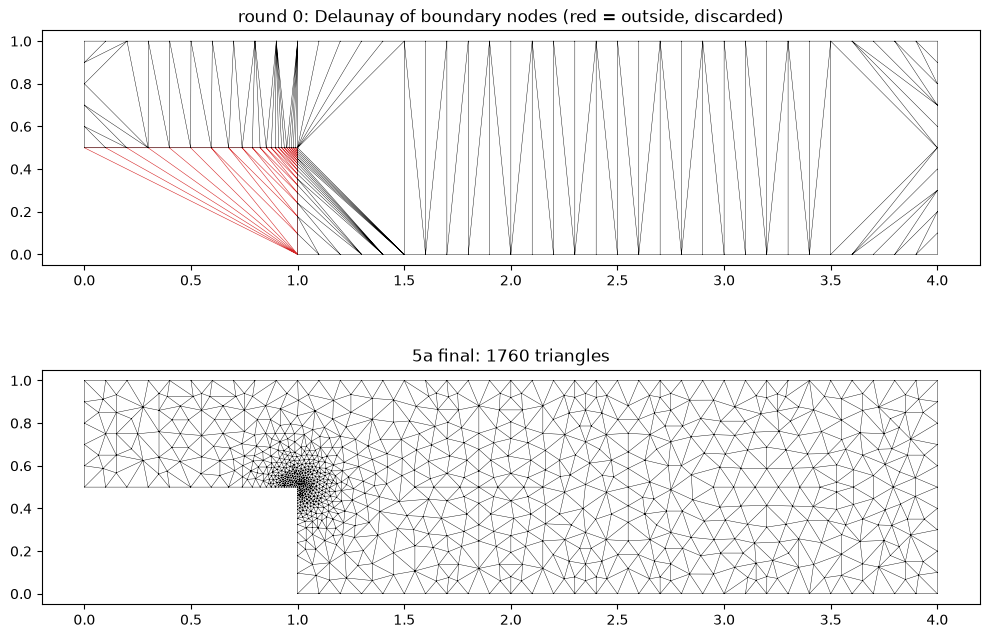

In [7]:
def plot_mesh(ax, P, tris, title, lw=0.3):
    ax.triplot(P[:, 0], P[:, 1], tris, lw=lw, color="k")
    ax.set_aspect("equal"); ax.set_title(title)


fig, axs = plt.subplots(2, 1, figsize=(10, 7))
all0 = make_ccw(bnodes, Delaunay(bnodes).simplices)
inside0 = loop.contains(bnodes[all0].mean(axis=1))
axs[0].triplot(bnodes[:, 0], bnodes[:, 1], all0[~inside0], lw=0.4, color="tab:red")
plot_mesh(axs[0], bnodes, all0[inside0], "round 0: Delaunay of boundary nodes (red = outside, discarded)")
plot_mesh(axs[1], P_a, tris_a, f"5a final: {len(tris_a)} triangles")
plt.tight_layout(); plt.show()

## Step 5b — Triangulation by gmsh

Same `Point`s, `Line`s and `CurveLoop` handed to gmsh's geometry kernel, same $h(x,y)$ handed
over as a Python size callback, and the patch names become physical groups. gmsh re-seeds
the boundary itself from $h$, so Step 4's nodes are only used by 5a.

gmsh takes the **minimum** over every size source it has (point sizes, curvature, boundary
extension, the callback) then clamps to `[MeshSizeMin, MeshSizeMax]`. The week 1 lesson:
switch the other sources off, or they silently override the field.

5b: 880 nodes, 1634 triangles, 124 boundary segments


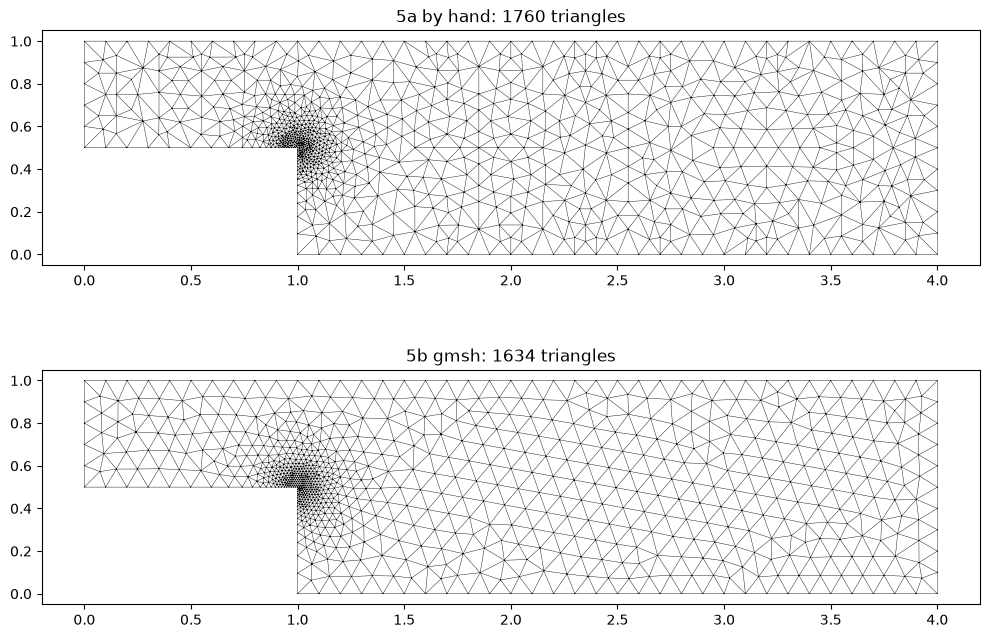

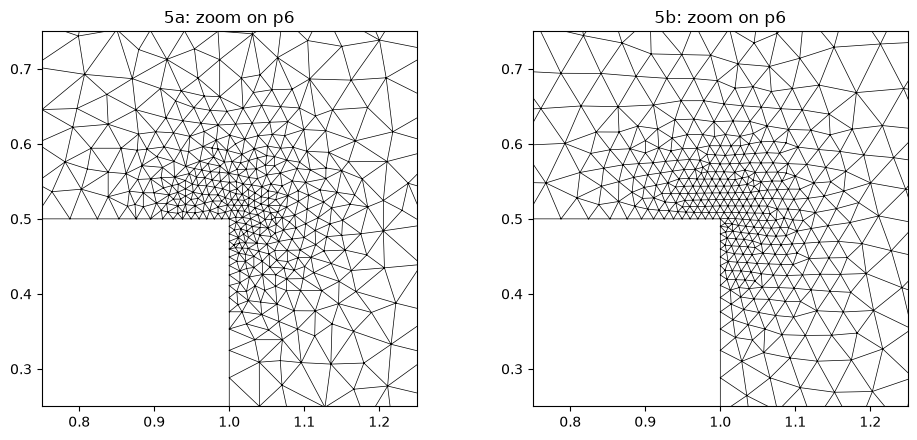

In [8]:
FIELD_ONLY = {
    "Mesh.MeshSizeFromPoints": 0,
    "Mesh.MeshSizeFromCurvature": 0,
    "Mesh.MeshSizeExtendFromBoundary": 0,
    "Mesh.MeshSizeMin": 0,
    "Mesh.MeshSizeMax": 1e22,
}


def mesh_with_gmsh(loops, h, options=None, boundary_layer=None, structured=()):
    """Mesh one CurveLoop, or several zone loops that share Lines, with gmsh.
    Returns (P, cells, segs, patch) like refine(). A zone with holes is a tuple (outer, hole, hole, ...).

    `options`        = extra gmsh settings layered on top of FIELD_ONLY (used for quads below).
    `boundary_layer` = settings for a BoundaryLayer field (hybrid mesh below); optional key "patches"
                       picks which patches grow layers (default: ("wall",)).
    `structured`     = 4-sided loops to mesh as structured quads (zoned mesh below).
    """
    zones = [loops] if isinstance(loops, (CurveLoop, tuple)) else list(loops)
    zones = [z if isinstance(z, tuple) else (z,) for z in zones]   # each zone: (outer, *holes)
    gmsh.initialize()
    try:
        gmsh.option.setNumber("General.Verbosity", 1)  # errors only
        gmsh.model.add("sudden_expansion")

        # Each Point and Line object becomes exactly ONE gmsh entity, however many loops use it.
        # That is what makes neighbouring zones share nodes along their common line.
        pt, ln = {}, {}  # Point -> gmsh point tag, Line -> gmsh curve tag

        def curve_tag(c):
            if isinstance(c, Reversed):
                return -curve_tag(c.line)              # negative tag = same curve, walked backwards
            if c not in ln:
                for p in (c.start, c.end) + ((c.centre,) if isinstance(c, Arc) else ()):
                    if p not in pt:
                        pt[p] = gmsh.model.geo.addPoint(p.x, p.y, 0.0)
                if isinstance(c, Arc):
                    ln[c] = gmsh.model.geo.addCircleArc(pt[c.start], pt[c.centre], pt[c.end])
                else:
                    ln[c] = gmsh.model.geo.addLine(pt[c.start], pt[c.end])
            return ln[c]

        # One plane surface per zone; its first curve loop is the outer boundary, the rest are holes.
        surfs = [gmsh.model.geo.addPlaneSurface([gmsh.model.geo.addCurveLoop([curve_tag(c) for c in L.curves])
                                                 for L in zone])
                 for zone in zones]
        gmsh.model.geo.synchronize()

        boundary = [(c, l) for c, l in ln.items() if c.patch is not None]  # interior cuts carry no patch
        for name in sorted({c.patch for c, _ in boundary}):
            gmsh.model.addPhysicalGroup(1, [l for c, l in boundary if c.patch == name], name=name)
        gmsh.model.addPhysicalGroup(2, surfs, name="fluid")

        for (L, *_), s in zip(zones, surfs):
            if any(L is z for z in structured):
                # Structured quads: opposite sides need the same node count, sized from h at the middle.
                if len(L.curves) != 4:
                    raise ValueError("a structured zone needs exactly 4 sides")
                n = [max(2, round(c.length / float(h(*c((0.5,))[0]))) + 1)
                     for c in (x.line if isinstance(x, Reversed) else x for x in L.curves)]
                for i, c in enumerate(L.curves):
                    gmsh.model.mesh.setTransfiniteCurve(abs(curve_tag(c)), max(n[i], n[(i + 2) % 4]))
                gmsh.model.mesh.setTransfiniteSurface(s)
                gmsh.model.mesh.setRecombine(2, s)     # merge the structured triangles pairwise into quads

        for k, v in {**FIELD_ONLY, **(options or {})}.items():
            gmsh.option.setNumber(k, v)
        gmsh.model.mesh.setSizeCallback(lambda dim, tag, x, y, z, lc: float(h(x, y)))

        if boundary_layer:
            (zone,) = zones  # ponytail: boundary layer only wired up for a single-zone domain (holes are fine)
            bl = dict(boundary_layer)
            layered = set(bl.pop("patches", ("wall",)))
            # Thin layers grown off the chosen curves; the size callback still sizes everything else.
            f = gmsh.model.mesh.field.add("BoundaryLayer")
            gmsh.model.mesh.field.setNumbers(f, "CurvesList", [ln[c] for L in zone for c in L.curves if c.patch in layered])
            # (incoming, outgoing) curve pairs at every vertex of every loop.
            corners = [(prev, c) for L in zone for prev, c in zip(L.curves[-1:] + L.curves[:-1], L.curves)]
            # Reflex corners (interior angle > 180 deg) need a fan of cells to close the gap between the
            # two curves' layers. The domain is on the left, so the boundary turns right there. Compare
            # the curves' TANGENTS at the joint, not their end points: the joints between a circle's arcs
            # are smooth (no turn at all), although the chords between them do turn.
            def turn(prev, c, eps=1e-6):
                t_in, t_out = prev(1.0) - prev(1.0 - eps), c(eps) - c(0.0)
                return _cross((0.0, 0.0), t_in, t_out) / (np.linalg.norm(t_in) * np.linalg.norm(t_out))  # sin(turn angle)
            reflex = [c.start for prev, c in corners if turn(prev, c) < -1e-3]
            gmsh.model.mesh.field.setNumbers(f, "FanPointsList", [pt[p] for p in reflex])
            # Where a layered curve meets an unlayered one (wall meets inlet/outlet) the layers must stop,
            # or gmsh wraps them around the wall's end into large skewed wedges.
            ends = [c.start for prev, c in corners if (prev.patch in layered) != (c.patch in layered)]
            gmsh.model.mesh.field.setNumbers(f, "PointsList", [pt[p] for p in ends])
            for k, v in bl.items():
                gmsh.model.mesh.field.setNumber(f, k, v)
            gmsh.model.mesh.field.setAsBoundaryLayer(f)
        gmsh.model.mesh.generate(2)

        # gmsh node tags are arbitrary integers; remap them to 0..N-1 row indices.
        tags, xyz, _ = gmsh.model.mesh.getNodes()
        index = np.zeros(int(tags.max()) + 1, dtype=int)
        index[tags.astype(int)] = np.arange(len(tags))
        P = xyz.reshape(-1, 3)[:, :2]

        # One block per element type present: 2 = 3-node triangle, 3 = 4-node quad.
        types, _, elem_nodes = gmsh.model.mesh.getElements(2)
        blocks = []
        for t, n in zip(types, elem_nodes):
            k = gmsh.model.mesh.getElementProperties(t)[3]          # nodes per element
            blocks.append(make_ccw(P, index[n.astype(int)].reshape(-1, k)))
        # One shape -> a plain (Nc, k) array. Mixed shapes -> a list holding one node array per cell.
        cells = blocks[0] if len(blocks) == 1 else [c for b in blocks for c in b]

        segs, patch = [], []
        for c, l in boundary:
            _, _, en = gmsh.model.mesh.getElements(1, l)          # line elements on this curve
            s = index[en[0].astype(int)].reshape(-1, 2)
            segs.append(s); patch += [c.patch] * len(s)
        return P, cells, np.vstack(segs), np.array(patch)
    finally:
        gmsh.finalize()


P_b, tris_b, segs_b, patch_b = mesh_with_gmsh(loop, h)
print(f"5b: {len(P_b)} nodes, {len(tris_b)} triangles, {len(segs_b)} boundary segments")

fig, axs = plt.subplots(2, 1, figsize=(10, 7))
plot_mesh(axs[0], P_a, tris_a, f"5a by hand: {len(tris_a)} triangles")
plot_mesh(axs[1], P_b, tris_b, f"5b gmsh: {len(tris_b)} triangles")
plt.tight_layout(); plt.show()

# Zoom on the step lip, where the attractor sits.
fig, axs = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, (P, t, name) in zip(axs, [(P_a, tris_a, "5a"), (P_b, tris_b, "5b")]):
    plot_mesh(ax, P, t, f"{name}: zoom on p6", lw=0.5)
    ax.set_xlim(p6.x - 0.25, p6.x + 0.25); ax.set_ylim(p6.y - 0.25, p6.y + 0.25)
plt.tight_layout(); plt.show()

## Step 6 — Finite-volume topology

A cell-centred FVM solver does not care about nodes; it loops over **faces** (edges in 2D).
For every face it needs:

- `owner`: the cell on one side. `neighbour`: the cell on the other side (internal faces only).
- $\mathbf{S}_f$: the face normal scaled by face length, pointing **from owner to neighbour**
  (outward for boundary faces).

Convention, as in OpenFOAM: internal faces first, sorted by (owner, neighbour) with
owner < neighbour; then boundary faces grouped by patch, each patch a contiguous range.

Orientation trick: each cell stores its nodes CCW, so walking edge $a \to b$ of a cell
keeps the cell on the **left**. The right-hand normal $(\Delta y, -\Delta x)$ therefore points
**out** of that cell. Storing each face with its *owner's* $a \to b$ order makes $\mathbf{S}_f$
point owner → neighbour for free.

In [9]:
@dataclass
class FvMesh:
    points: np.ndarray     # (Np, 2) node coordinates
    cells: object          # node indices per cell, CCW: (Nc, k) array, or list of arrays if shapes mix
    faces: np.ndarray      # (Nf, 2) node indices, in the owner's CCW order
    owner: np.ndarray      # (Nf,)   owner cell of every face
    neighbour: np.ndarray  # (Ni,)   neighbour cell of the first Ni (internal) faces
    patches: dict          # name -> (start, count) into the boundary part of faces
    Sf: np.ndarray         # (Nf, 2) area vector, owner -> neighbour / outward
    Cf: np.ndarray         # (Nf, 2) face centre
    C: np.ndarray          # (Nc, 2) cell centroid
    V: np.ndarray          # (Nc,)   cell area ("volume" in 2D)

    @property
    def n_internal(self):
        return len(self.neighbour)


def build_fv_mesh(P, cells, segs, patch):
    # Collect, for every undirected edge, the cells that use it and in which direction.
    # ponytail: Python dict over 3 * Nc edges; np.unique on sorted edge keys if this gets slow.
    users = {}  # (min node, max node) -> [(cell, a, b), ...]
    for c, cell in enumerate(cells):
        for a, b in zip(cell, np.roll(cell, -1)):     # consecutive nodes = the cell's edges
            users.setdefault((min(a, b), max(a, b)), []).append((c, a, b))
    patch_of = {(min(a, b), max(a, b)): str(p) for (a, b), p in zip(segs, patch)}

    internal, boundary = [], []
    for key, u in users.items():
        if len(u) == 2:
            (c0, a, b), (c1, _, _) = sorted(u)        # owner = lower cell index
            internal.append((c0, c1, a, b))
        elif len(u) == 1:
            if key not in patch_of:
                raise ValueError(f"edge {key} is on the mesh boundary but on no patch: mesh does not conform")
            c0, a, b = u[0]
            boundary.append((patch_of[key], c0, a, b))
        else:
            raise ValueError(f"edge {key} shared by {len(u)} cells")
    if len(boundary) != len(patch_of):
        raise ValueError("some boundary segments are not mesh edges")

    internal.sort()
    boundary.sort()
    owner = np.array([f[0] for f in internal] + [f[1] for f in boundary])
    neighbour = np.array([f[1] for f in internal])
    faces = np.array([f[2:] for f in internal] + [f[2:] for f in boundary])
    patches, start = {}, len(internal)
    for name in sorted({f[0] for f in boundary}):
        n = sum(f[0] == name for f in boundary)
        patches[name] = (start, n)
        start += n

    d = P[faces[:, 1]] - P[faces[:, 0]]
    Sf = np.c_[d[:, 1], -d[:, 0]]                      # right-hand normal x length
    Cf = 0.5 * (P[faces[:, 0]] + P[faces[:, 1]])
    # Polygon area and centroid (shoelace), one cell at a time so triangles and quads can mix.
    # For a triangle the centroid is just the vertex mean; for a quad only if it is a parallelogram.
    # ponytail: Python loop per cell; group cells by node count and vectorise if this gets slow.
    V, C = np.zeros(len(cells)), np.zeros((len(cells), 2))
    for c, cell in enumerate(cells):
        x, y = P[cell, 0], P[cell, 1]
        x1, y1 = np.roll(x, -1), np.roll(y, -1)
        cr = x * y1 - x1 * y
        V[c] = 0.5 * cr.sum()
        C[c] = ((x + x1) * cr).sum() / (6 * V[c]), ((y + y1) * cr).sum() / (6 * V[c])
    return FvMesh(P, cells, faces, owner, neighbour, patches, Sf, Cf, C, V)


fv_a = build_fv_mesh(P_a, tris_a, segs_a, patch_a)
fv_b = build_fv_mesh(P_b, tris_b, segs_b, patch_b)
for name, m in [("5a", fv_a), ("5b", fv_b)]:
    print(f"{name}: {len(m.cells)} cells, {len(m.faces)} faces ({m.n_internal} internal), patches {m.patches}")

m = fv_a
print("\nfirst 5 internal faces of 5a:")
print(" face  owner  neighbour         Sf")
for f in range(5):
    print(f"{f:5d}  {m.owner[f]:5d}  {m.neighbour[f]:9d}   ({m.Sf[f, 0]:+.4f}, {m.Sf[f, 1]:+.4f})")

5a: 1760 cells, 2702 faces (2578 internal), patches {'inlet': (2578, 5), 'outlet': (2583, 10), 'wall': (2593, 109)}
5b: 1634 cells, 2513 faces (2389 internal), patches {'inlet': (2389, 5), 'outlet': (2394, 10), 'wall': (2404, 109)}

first 5 internal faces of 5a:
 face  owner  neighbour         Sf
    0      0         30   (+0.0130, +0.1102)
    1      0        221   (+0.0534, -0.0401)
    2      0        408   (-0.0664, -0.0702)
    3      1          2   (+0.0875, -0.0125)
    4      1         10   (-0.0875, -0.0875)


## Step 7 — Checks

Exact identities a valid FV mesh must satisfy (to round-off):

1. **Closed cells**: $\sum_{f \in \text{cell}} \mathbf{S}_f = 0$ (sign flipped when the cell is the neighbour).
2. **Divergence theorem** on $\mathbf{x}$: $\sum_f \mathbf{S}_f \cdot \mathbf{x}_f = \int \nabla\cdot\mathbf{x}\,dV = 2V$ in 2D. Catches wrong normals *and* wrong face centres.
3. **Total area** $\sum V = L_1 H_1 + L_2 H_2$, every $V > 0$.
4. **Patch lengths**: inlet $= H_1$, outlet $= H_2$, and the closed boundary's $\sum \mathbf{S}_f = 0$.
5. **Owner < neighbour** on every internal face.

In [10]:
def check_fv_mesh(m, exact_area, expected_patch_length, tol=1e-10):
    ni = m.n_internal
    net = np.zeros_like(m.C)
    np.add.at(net, m.owner, m.Sf)
    np.add.at(net, m.neighbour, -m.Sf[:ni])
    div = np.zeros_like(m.V)
    flux = (m.Sf * m.Cf).sum(axis=1)
    np.add.at(div, m.owner, flux)
    np.add.at(div, m.neighbour, -flux[:ni])
    patch_len = {k: float(np.linalg.norm(m.Sf[s:s + n], axis=1).sum()) for k, (s, n) in m.patches.items()}
    results = {
        "cells closed: max |sum Sf|": (np.abs(net).max(), np.abs(net).max() < tol),
        "div theorem: max |sum Sf.xf - 2V|": (np.abs(div - 2 * m.V).max(), np.abs(div - 2 * m.V).max() < tol),
        "min cell area > 0": (m.V.min(), m.V.min() > 0),
        "total area error": (abs(m.V.sum() - exact_area), abs(m.V.sum() - exact_area) < tol),
        "boundary closed: |sum Sf|": (np.linalg.norm(m.Sf[ni:].sum(0)), np.linalg.norm(m.Sf[ni:].sum(0)) < tol),
        "owner < neighbour": (int((m.owner[:ni] >= m.neighbour).sum()), bool((m.owner[:ni] < m.neighbour).all())),
    }
    for k, L in expected_patch_length.items():
        results[f"patch {k} length error"] = (abs(patch_len[k] - L), abs(patch_len[k] - L) < tol)
    return results


L1, L2, H1, H2 = (PARAMS[k] for k in ("L1", "L2", "H1", "H2"))
expected_patch_length = {
    "inlet": H1,
    "outlet": H2,
    "wall": L2 + (H2 - H1) + L1 + (L1 + L2),  # bottom + step face + inlet floor + top
}

all_ok = True
for name, m in [("5a", fv_a), ("5b", fv_b)]:
    print(f"--- {name}")
    for k, (val, ok) in check_fv_mesh(m, exact_area, expected_patch_length).items():
        print(f"  {'ok ' if ok else 'BAD'} {k}: {val:.3e}")
        all_ok &= bool(ok)
assert all_ok, "an FV mesh check failed"

--- 5a
  ok  cells closed: max |sum Sf|: 1.388e-17
  ok  div theorem: max |sum Sf.xf - 2V|: 9.992e-16
  ok  min cell area > 0: 1.616e-05
  ok  total area error: 0.000e+00
  ok  boundary closed: |sum Sf|: 1.110e-16
  ok  owner < neighbour: 0.000e+00
  ok  patch inlet length error: 0.000e+00
  ok  patch outlet length error: 0.000e+00
  ok  patch wall length error: 1.776e-15
--- 5b
  ok  cells closed: max |sum Sf|: 0.000e+00
  ok  div theorem: max |sum Sf.xf - 2V|: 7.216e-16
  ok  min cell area > 0: 2.377e-05
  ok  total area error: 0.000e+00
  ok  boundary closed: |sum Sf|: 0.000e+00
  ok  owner < neighbour: 0.000e+00
  ok  patch inlet length error: 0.000e+00
  ok  patch outlet length error: 0.000e+00
  ok  patch wall length error: 0.000e+00


### Did the meshes follow $h$? And are the triangles any good?

Realised size of a cell: the side of the equilateral triangle with the same area,
$h_{\text{mesh}} = \sqrt{4V/\sqrt3}$. Ratio $h_{\text{mesh}} / h(\text{centroid})$ near 1 means
the mesher did what we asked; the minimum angle measures shape quality (60° is perfect).

5a by hand: h_mesh/h median 0.90 (5-95%: 0.68-1.14), min angle 24.6 deg, median 46.7 deg
5b gmsh: h_mesh/h median 0.97 (5-95%: 0.81-1.07), min angle 35.2 deg, median 54.9 deg


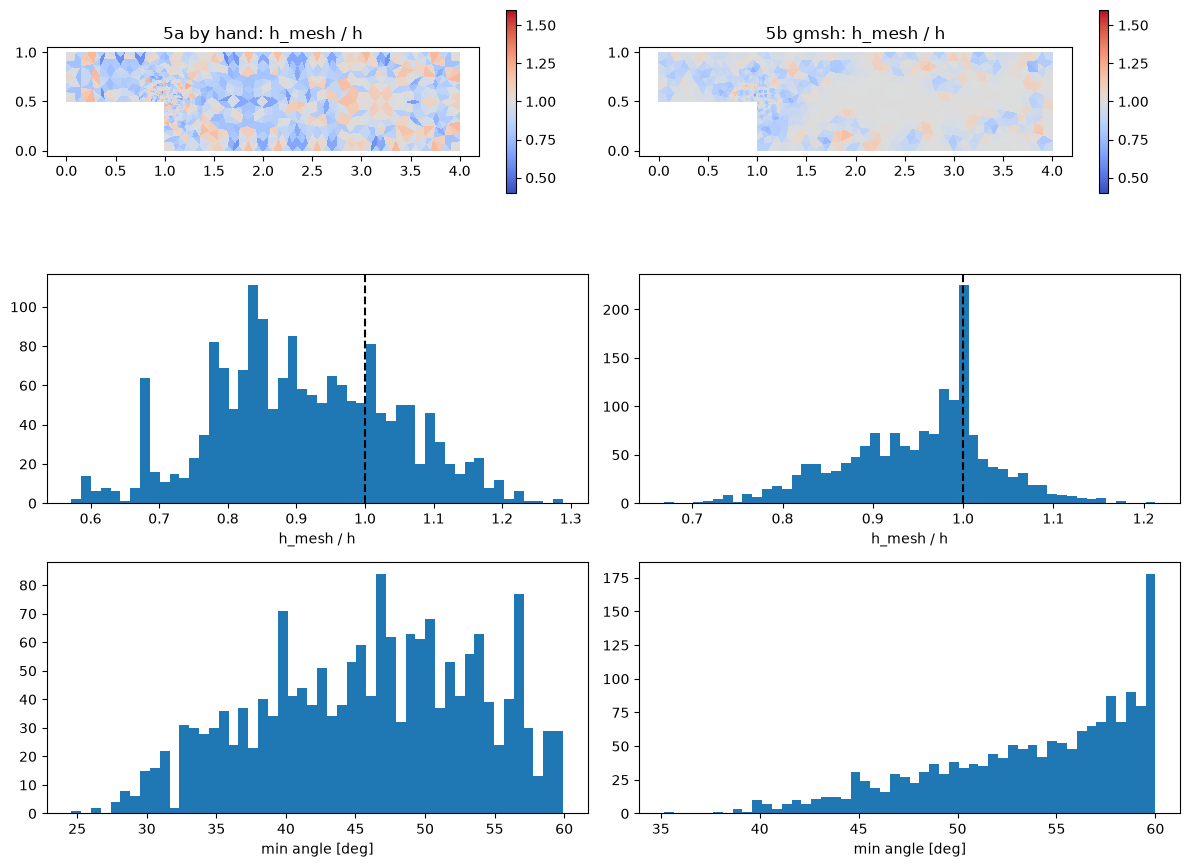

In [11]:
def min_angles_deg(P, tris):
    a, b, c = P[tris[:, 0]], P[tris[:, 1]], P[tris[:, 2]]
    def ang(p, q, r):  # angle at p
        u, v = q - p, r - p
        return np.degrees(np.arccos(np.clip((u * v).sum(1) / np.linalg.norm(u, axis=1) / np.linalg.norm(v, axis=1), -1, 1)))
    return np.minimum.reduce([ang(a, b, c), ang(b, c, a), ang(c, a, b)])


fig, axs = plt.subplots(3, 2, figsize=(12, 9), gridspec_kw=dict(height_ratios=[1, 1, 1.1]))
for col, (name, m) in enumerate([("5a by hand", fv_a), ("5b gmsh", fv_b)]):
    ratio = np.sqrt(4 * m.V / np.sqrt(3)) / h(*m.C.T)
    ang = min_angles_deg(m.points, m.cells)
    print(f"{name}: h_mesh/h median {np.median(ratio):.2f} (5-95%: {np.percentile(ratio, 5):.2f}-{np.percentile(ratio, 95):.2f}), "
          f"min angle {ang.min():.1f} deg, median {np.median(ang):.1f} deg")

    tp = axs[0, col].tripcolor(m.points[:, 0], m.points[:, 1], m.cells, facecolors=ratio, cmap="coolwarm", vmin=0.4, vmax=1.6)
    axs[0, col].set_aspect("equal"); axs[0, col].set_title(f"{name}: h_mesh / h")
    fig.colorbar(tp, ax=axs[0, col], shrink=0.8)

    axs[1, col].hist(ratio, bins=50); axs[1, col].set_xlabel("h_mesh / h"); axs[1, col].axvline(1, color="k", ls="--")
    axs[2, col].hist(ang, bins=50); axs[2, col].set_xlabel("min angle [deg]")
plt.tight_layout(); plt.show()

## Bonus — quadrilateral cells

Same geometry, same $h$, same FV builder; only gmsh's settings change. gmsh does not lay quads
down directly, it **triangulates first, then merges pairs of neighbouring triangles**:

- `Mesh.Algorithm = 8` ("Frontal-Delaunay for quads") places nodes so triangles come out as
  right-angled halves of squares, which pair up into near-squares.
- `Mesh.RecombineAll = 1` turns the merging on.
- `Mesh.RecombinationAlgorithm = 3` ("Blossom full-quad") meshes at roughly **twice** $h$, merges
  pairs, then **splits every element into quads** (triangle → 3, quad → 4). That last split is what
  guarantees no triangle survives, and it brings the size back down to $h$.

  *Blossom* means choosing the pairs by minimum-cost perfect matching on the triangle adjacency
  graph. A perfect matching needs an **even** number of triangles; here gmsh gets an odd count, prints
  `Cannot apply Blossom: odd number of triangles`, and pairs greedily instead. That warning is
  expected and harmless: the final split still yields all quads. (Plain Blossom, setting `1`, avoids
  the warning but gave fewer near-square cells on this domain: 74% vs 85%.)

Step 6 needed no special case: a cell is just a CCW polygon, its faces are consecutive node pairs,
and the centroid uses the polygon formula. All Step 7 identities hold for any polygon.

Size is now $h_{\text{mesh}} = \sqrt{V}$ (a square of side $h$ has area $h^2$); shape is the corner
angles, 90° being a perfect square.

Not done: a *structured* grid (three rectangular blocks, transfinite meshing). Perfect rectangles,
but each block can only be graded along its edges, so it cannot follow the attractor-based $h$.

quads: 693 cells (4 nodes each), 1449 faces (1323 internal), patches {'inlet': (1323, 6), 'outlet': (1329, 10), 'wall': (1339, 110)}
  ok  cells closed: max |sum Sf|: 0.000e+00
  ok  div theorem: max |sum Sf.xf - 2V|: 6.384e-16
  ok  min cell area > 0: 5.459e-05
  ok  total area error: 0.000e+00
  ok  boundary closed: |sum Sf|: 8.327e-17
  ok  owner < neighbour: 0.000e+00
  ok  patch inlet length error: 0.000e+00
  ok  patch outlet length error: 0.000e+00
  ok  patch wall length error: 1.776e-15
h_mesh/h median 1.00 (5-95%: 0.74-1.10); corner angles 45.0-134.8 deg; 85% of cells have every corner within 20 deg of 90


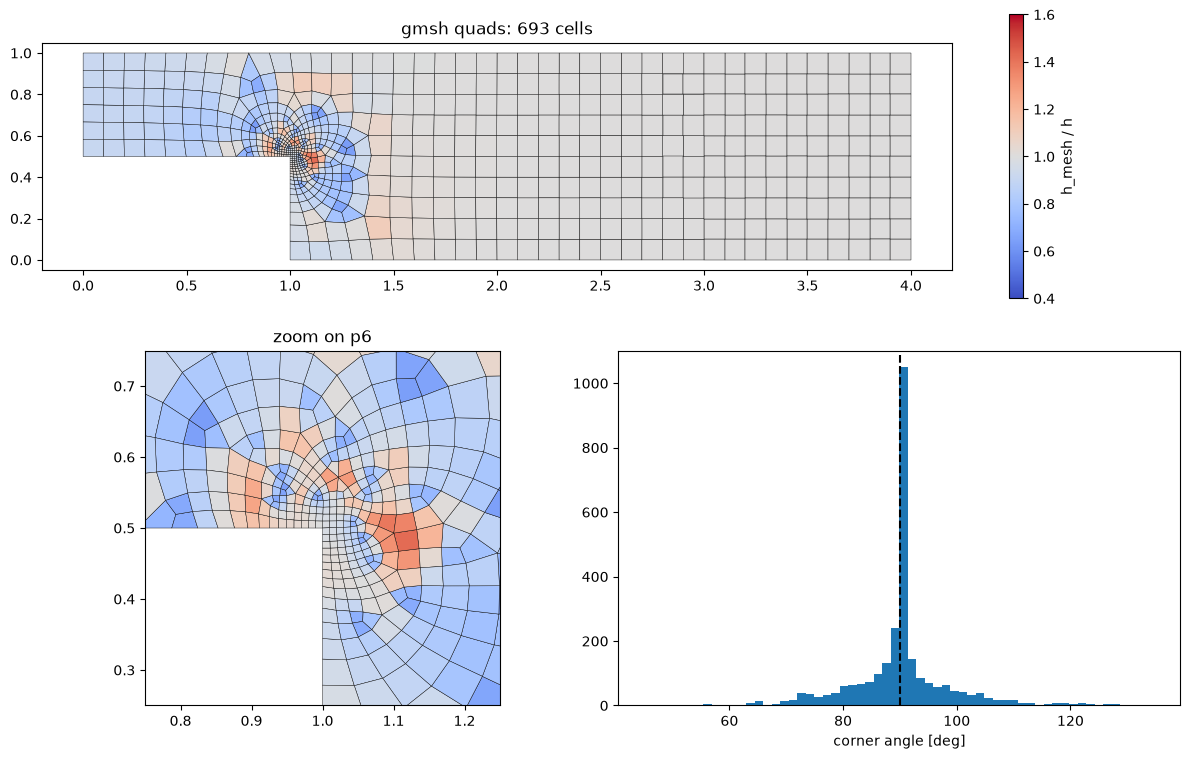

In [12]:
from matplotlib.collections import PolyCollection

QUADS = {
    "Mesh.Algorithm": 8,               # Frontal-Delaunay for quads: right-angled triangles that pair well
    "Mesh.RecombineAll": 1,            # merge triangle pairs into quads
    "Mesh.RecombinationAlgorithm": 3,  # full-quad: pair, then split every cell into quads -> no triangles left
}
P_q, quads, segs_q, patch_q = mesh_with_gmsh(loop, h, QUADS)
fv_q = build_fv_mesh(P_q, quads, segs_q, patch_q)
print(f"quads: {len(fv_q.cells)} cells ({fv_q.cells.shape[1]} nodes each), "
      f"{len(fv_q.faces)} faces ({fv_q.n_internal} internal), patches {fv_q.patches}")

# Same identities as Step 7: closure, divergence theorem, areas, patch lengths, owner < neighbour.
results = check_fv_mesh(fv_q, exact_area, expected_patch_length)
for k, (val, ok) in results.items():
    print(f"  {'ok ' if ok else 'BAD'} {k}: {val:.3e}")
assert all(ok for _, ok in results.values()), "an FV mesh check failed"

# Size and shape.
ratio = np.sqrt(fv_q.V) / h(*fv_q.C.T)
xy = P_q[quads]                                                        # (Nc, 4, 2) corner coordinates
u, v = np.roll(xy, 1, axis=1) - xy, np.roll(xy, -1, axis=1) - xy      # corner -> previous / next corner
cos = (u * v).sum(-1) / (np.linalg.norm(u, axis=-1) * np.linalg.norm(v, axis=-1))
corner = np.degrees(np.arccos(np.clip(cos, -1, 1)))                   # (Nc, 4) corner angles
print(f"h_mesh/h median {np.median(ratio):.2f} (5-95%: {np.percentile(ratio, 5):.2f}-{np.percentile(ratio, 95):.2f}); "
      f"corner angles {corner.min():.1f}-{corner.max():.1f} deg; "
      f"{np.mean(np.abs(corner - 90).max(axis=1) < 20):.0%} of cells have every corner within 20 deg of 90")

# Pictures: whole mesh coloured by h_mesh / h, zoom on the step lip, corner-angle histogram.
fig = plt.figure(figsize=(12, 8))
ax_full, ax_zoom, ax_hist = fig.add_subplot(2, 1, 1), fig.add_subplot(2, 2, 3), fig.add_subplot(2, 2, 4)
for ax in (ax_full, ax_zoom):
    pc = PolyCollection(xy, array=ratio, cmap="coolwarm", norm=plt.Normalize(0.4, 1.6), edgecolors="k", linewidths=0.3)
    ax.add_collection(pc)
    ax.set_aspect("equal"); ax.autoscale_view()
fig.colorbar(pc, ax=ax_full, shrink=0.8, label="h_mesh / h")
ax_full.set_title(f"gmsh quads: {len(quads)} cells")
ax_zoom.set_xlim(p6.x - 0.25, p6.x + 0.25); ax_zoom.set_ylim(p6.y - 0.25, p6.y + 0.25); ax_zoom.set_title("zoom on p6")
ax_hist.hist(corner.ravel(), bins=60); ax_hist.axvline(90, color="k", ls="--"); ax_hist.set_xlabel("corner angle [deg]")
plt.tight_layout(); plt.show()

## Bonus — hybrid mesh: quad boundary layer + triangle core

The CFD reason to mix shapes: next to a wall the velocity changes fast **normal** to the wall and
slowly **along** it. Thin, wall-aligned quads resolve that normal gradient cheaply; triangles fill the
rest of the domain, where flexibility matters more than alignment.

gmsh's `BoundaryLayer` field grows layers off the wall curves before the core is triangulated:

| setting | meaning |
|---|---|
| `Size` | thickness of the first layer, touching the wall |
| `Ratio` | each layer is this much thicker than the one below it |
| `Thickness` | stop adding layers once the stack is this thick |
| `Quads = 1` | keep the layers as quads (0 splits them into triangles) |

**Fans at reflex corners.** At $p_6$ the wall turns *away* from the fluid (interior angle 270°), so the
layers grown from the two walls would leave a wedge-shaped gap. gmsh fills it with a fan of quads.
`mesh_with_gmsh` finds such corners itself: walking a CCW loop, you turn *right* at a reflex corner.

**Layer ends.** Where a wall meets the inlet or outlet ($p_2, p_3, p_4, p_5$) the layers must stop.
Without listing those points in `PointsList`, gmsh wraps the layers around the wall's end into large,
badly skewed wedges, and the mesh still passes every Step 7 check, since they test consistency, not
quality. Look at the picture.

**Mixed shapes.** `cells` is now a list with one node array per cell. Step 6 already walks each cell's
edges and computes its area and centroid one cell at a time, so the FV builder and Step 7's checks run
unchanged.

**Boundary-layer check.** For a wall-aligned quad the centroid sits at mid-height, so the first-layer
height is $\approx 2\,(\mathbf{x}_f - \mathbf{x}_C)\cdot\hat{\mathbf{n}}$ over the wall faces. That is the number that sets $y^+$.

hybrid: 1442 triangles + 674 quads = 2116 cells, 3585 faces (3437 internal), patches {'inlet': (3437, 17), 'outlet': (3454, 22), 'wall': (3476, 109)}
  ok  cells closed: max |sum Sf|: 1.388e-17
  ok  div theorem: max |sum Sf.xf - 2V|: 1.485e-15
  ok  min cell area > 0: 7.654e-07
  ok  total area error: 0.000e+00
  ok  boundary closed: |sum Sf|: 2.220e-16
  ok  owner < neighbour: 0.000e+00
  ok  patch inlet length error: 0.000e+00
  ok  patch outlet length error: 2.220e-16
  ok  patch wall length error: 0.000e+00
shortest face 7.80e-04 (0 would mean a collapsed fan cell)
wall faces owned by a quad: 100%; first-layer height median 0.0020 (5-95%: 0.0020-0.0020), asked 0.002


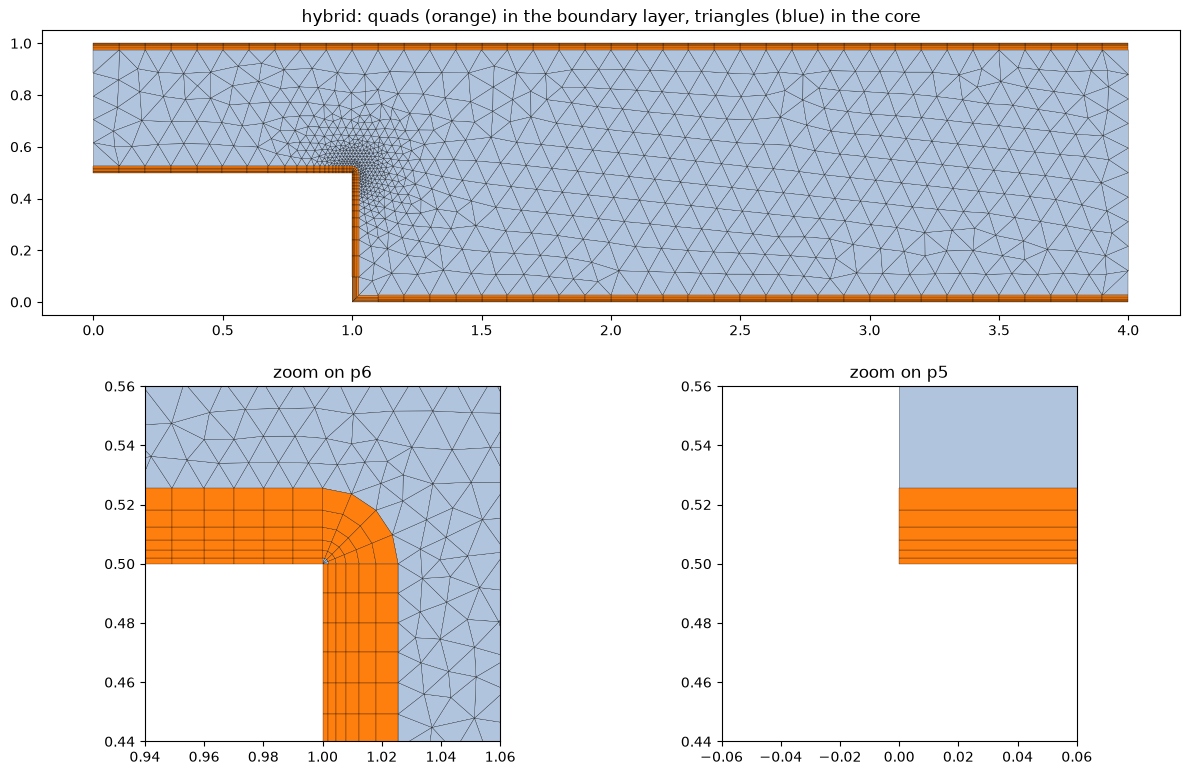

In [13]:
BOUNDARY_LAYER = dict(
    Size=0.002,      # first layer thickness next to the wall
    Ratio=1.3,       # growth ratio between consecutive layers
    Thickness=0.03,  # total stack thickness
    Quads=1,         # quads in the layers, triangles in the core
)
P_hy, cells_hy, segs_hy, patch_hy = mesh_with_gmsh(loop, h, boundary_layer=BOUNDARY_LAYER)
fv_hy = build_fv_mesh(P_hy, cells_hy, segs_hy, patch_hy)
n_nodes = np.array([len(c) for c in fv_hy.cells])                    # 3 = triangle, 4 = quad
print(f"hybrid: {np.sum(n_nodes == 3)} triangles + {np.sum(n_nodes == 4)} quads = {len(n_nodes)} cells, "
      f"{len(fv_hy.faces)} faces ({fv_hy.n_internal} internal), patches {fv_hy.patches}")

# Same identities as Step 7.
results = check_fv_mesh(fv_hy, exact_area, expected_patch_length)
for k, (val, ok) in results.items():
    print(f"  {'ok ' if ok else 'BAD'} {k}: {val:.3e}")
assert all(ok for _, ok in results.values()), "an FV mesh check failed"

# Boundary layer: is every wall cell a quad, and how thick is the first layer?
s, n = fv_hy.patches["wall"]
wall_cell = fv_hy.owner[s:s + n]
nhat = fv_hy.Sf[s:s + n] / np.linalg.norm(fv_hy.Sf[s:s + n], axis=1, keepdims=True)
first = 2 * ((fv_hy.Cf[s:s + n] - fv_hy.C[wall_cell]) * nhat).sum(axis=1)
print(f"shortest face {np.linalg.norm(fv_hy.Sf, axis=1).min():.2e} (0 would mean a collapsed fan cell)")
print(f"wall faces owned by a quad: {np.mean(n_nodes[wall_cell] == 4):.0%}; first-layer height "
      f"median {np.median(first):.4f} (5-95%: {np.percentile(first, 5):.4f}-{np.percentile(first, 95):.4f}), "
      f"asked {BOUNDARY_LAYER['Size']}")

# Pictures: cell type colouring, whole domain plus zooms on the reflex corner p6 and the inlet corner p5.
colour = np.where(n_nodes == 4, "tab:orange", "lightsteelblue")
fig = plt.figure(figsize=(12, 8))
ax_full, ax_p6, ax_p5 = fig.add_subplot(2, 1, 1), fig.add_subplot(2, 2, 3), fig.add_subplot(2, 2, 4)
for ax in (ax_full, ax_p6, ax_p5):
    ax.add_collection(PolyCollection([P_hy[c] for c in fv_hy.cells], facecolors=colour, edgecolors="k", linewidths=0.2))
    ax.set_aspect("equal"); ax.autoscale_view()
ax_full.set_title("hybrid: quads (orange) in the boundary layer, triangles (blue) in the core")
for ax, p, w in ((ax_p6, p6, 0.06), (ax_p5, p5, 0.06)):
    ax.set_xlim(p.x - w, p.x + w); ax.set_ylim(p.y - w, p.y + w); ax.set_title(f"zoom on {p.name}")
plt.tight_layout(); plt.show()

## Bonus — zoned mesh: each shape where it pays off

Not "triangles in the first half, quads in the second" but **quads → triangles → quads**, because the
value of each shape depends on the local flow and the local size field:

| zone | flow there | best shape | why |
|---|---|---|---|
| inlet channel, $x < L_1 - d_{\max}$ | parallel, fully developed | structured quads | grid lines follow the flow → least numerical diffusion; about half the cells of triangles for the same $h$ |
| around the step lip, $\lvert x - L_1\rvert < d_{\max}$ | separation, recirculation, every direction | triangles | handle $h$ grading 10× in a short distance; no preferred direction to align to anyway |
| downstream, $x > L_1 + d_{\max}$ | recovering to parallel | structured quads | same as the inlet |

The cuts sit at $x = L_1 \pm d_{\max}$ on purpose: beyond distance $d_{\max}$ from $p_6$ the size field is
exactly $h_{\max}$, so uniform structured quads match the request with no compromise. (The downstream
cut is conservative: in a real run, reattachment sits roughly 6–8 step heights downstream, and you would
move cut B past it once a first solution shows where it is.)

**Topology, for real this time.** Three `CurveLoop`s share two interior lines, `cut_a` and `cut_b`.
Each cut is **one** `Line` object: the zone on its left walks it forwards, the zone on its right walks
`-cut_a`, a `Reversed` view of the same object. `mesh_with_gmsh` turns each Line object into exactly one
gmsh curve (`-cut_a` becomes a negative curve tag), so both zones get the *same* nodes on the cut and the
mesh is conforming: every cut edge becomes an ordinary internal face with a quad on one side and a
triangle on the other. Two separate lines that merely had the same coordinates would mesh independently
and leave mismatched nodes, the textbook's *"geometrical coincidence alone is insufficient"* in action.

Interior cuts have `patch=None`, so they never become boundary faces.

**Other polygons.** The next step up would be *polygonal* cells in the step zone: the dual of the
triangle mesh (one cell per triangle-mesh node, built from the triangle centroids and edge midpoints
around it). Each cell then has 5–7 neighbours, which makes gradient reconstruction better and less
sensitive to flow direction; that is why polyhedral meshes are popular in CFD. Not built here.

zoned: 952 triangles + 275 quads = 1227 cells (all-triangle 5b: 1634), 2040 faces (1916 internal), patches {'inlet': (1916, 5), 'outlet': (1921, 10), 'wall': (1931, 109)}
  ok  cells closed: max |sum Sf|: 0.000e+00
  ok  div theorem: max |sum Sf.xf - 2V|: 1.110e-15
  ok  min cell area > 0: 2.806e-05
  ok  total area error: 0.000e+00
  ok  boundary closed: |sum Sf|: 0.000e+00
  ok  owner < neighbour: 0.000e+00
  ok  patch inlet length error: 0.000e+00
  ok  patch outlet length error: 0.000e+00
  ok  patch wall length error: 1.776e-15
faces on the cuts: 15, of which quad|triangle: 15
  quads: h_mesh/h median 1.00 (5-95%: 1.00-1.00)
  triangles: h_mesh/h median 0.95 (5-95%: 0.80-1.08)


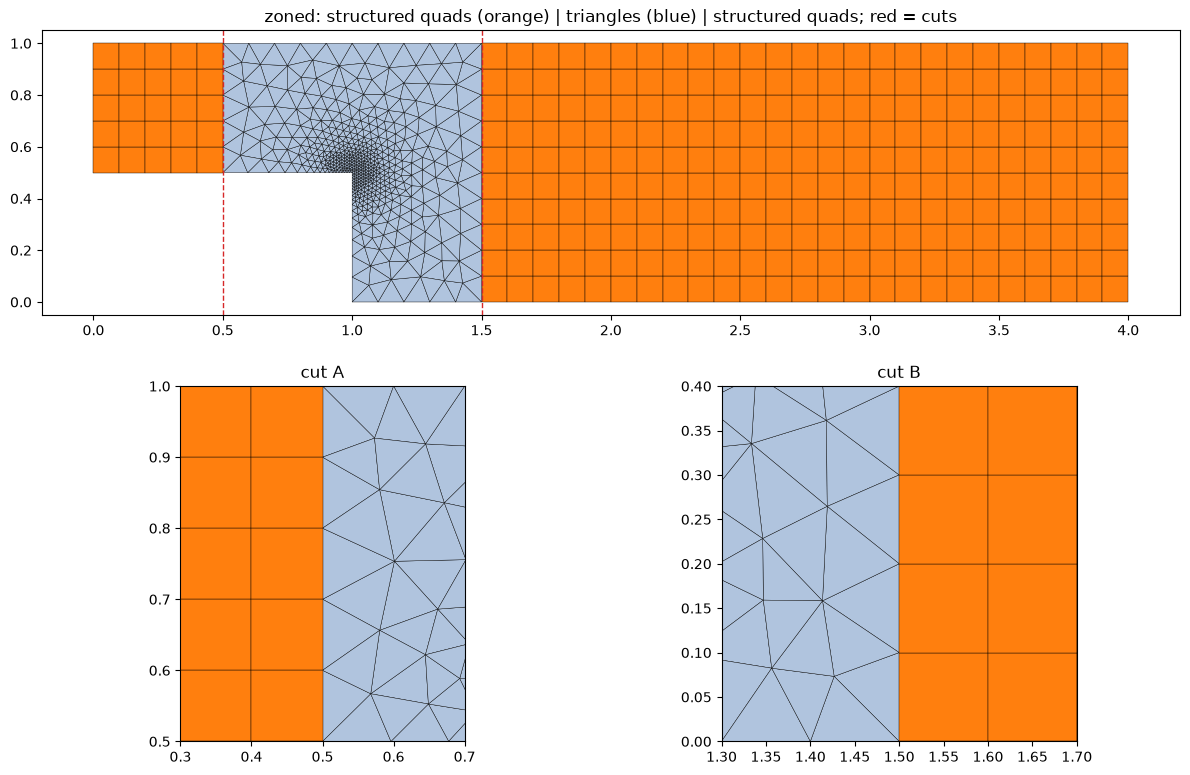

In [14]:
# Cut positions: where the size field stops changing. Must match make_size_field's dmax / hmax;
# the assert further down checks that h really is constant inside the quad zones.
D_MAX, H_MAX = 0.5, 0.1
xa, xb = p6.x - D_MAX, p6.x + D_MAX
if not (0 < xa and xb < L1 + L2):
    raise ValueError("domain too short for the triangle zone; shrink D_MAX or lengthen L1 / L2")

a_lo, a_hi = Point("a_lo", xa, p5.y), Point("a_hi", xa, H2)    # cut A, across the inlet channel
b_lo, b_hi = Point("b_lo", xb, 0.0), Point("b_hi", xb, H2)     # cut B, across the downstream channel
cut_a = Line(a_lo, a_hi, None)                                 # interior: no patch
cut_b = Line(b_lo, b_hi, None)

# Every loop CCW. Each cut is walked forwards by the zone on its left and backwards (-cut) by the zone on its right.
inlet_block = CurveLoop([Line(p5, a_lo, "wall"), cut_a, Line(a_hi, p4, "wall"), Line(p4, p5, "inlet")])
step_zone = CurveLoop([Line(a_lo, p6, "wall"), Line(p6, p1, "wall"), Line(p1, b_lo, "wall"), cut_b,
                       Line(b_hi, a_hi, "wall"), -cut_a])
outlet_block = CurveLoop([Line(b_lo, p2, "wall"), Line(p2, p3, "outlet"), Line(p3, b_hi, "wall"), -cut_b])
zones = {"inlet block (quads)": inlet_block, "step zone (triangles)": step_zone, "outlet block (quads)": outlet_block}

zone_area = sum(z.signed_area() for z in zones.values())
assert abs(zone_area - exact_area) < 1e-12, "zones must tile the domain exactly"
for name in ("inlet block (quads)", "outlet block (quads)"):
    z = zones[name]
    xy = np.array([p.xy for p in z.vertices])
    gx, gy = np.meshgrid(np.linspace(xy[:, 0].min(), xy[:, 0].max(), 50),   # the blocks are rectangles,
                         np.linspace(xy[:, 1].min(), xy[:, 1].max(), 50))   # so their bounding box is exact
    assert np.allclose(h(gx, gy), H_MAX), f"h is not constant in the {name}; move the cuts"

P_z, cells_z, segs_z, patch_z = mesh_with_gmsh(list(zones.values()), h, structured=[inlet_block, outlet_block])
fv_z = build_fv_mesh(P_z, cells_z, segs_z, patch_z)
n_nodes = np.array([len(c) for c in fv_z.cells])
print(f"zoned: {np.sum(n_nodes == 3)} triangles + {np.sum(n_nodes == 4)} quads = {len(n_nodes)} cells "
      f"(all-triangle 5b: {len(fv_b.cells)}), {len(fv_z.faces)} faces ({fv_z.n_internal} internal), patches {fv_z.patches}")

results = check_fv_mesh(fv_z, exact_area, expected_patch_length)
for k, (val, ok) in results.items():
    print(f"  {'ok ' if ok else 'BAD'} {k}: {val:.3e}")
assert all(ok for _, ok in results.values()), "an FV mesh check failed"

# Conformity across the cuts: every cut edge must be an internal face with a quad on one side and a
# triangle on the other. A non-conforming seam would show up as unmatched boundary edges above instead.
on_cut = np.isclose(fv_z.Cf[:fv_z.n_internal, 0], xa) | np.isclose(fv_z.Cf[:fv_z.n_internal, 0], xb)
mixed = n_nodes[fv_z.owner[:fv_z.n_internal][on_cut]] + n_nodes[fv_z.neighbour[on_cut]] == 7
print(f"faces on the cuts: {on_cut.sum()}, of which quad|triangle: {mixed.sum()}")
assert on_cut.sum() > 0 and mixed.all()

# Size: equal-area square side for quads, equal-area equilateral side for triangles.
h_mesh = np.where(n_nodes == 4, np.sqrt(fv_z.V), np.sqrt(4 * fv_z.V / np.sqrt(3)))
ratio = h_mesh / h(*fv_z.C.T)
for k, kind in ((4, "quads"), (3, "triangles")):
    print(f"  {kind}: h_mesh/h median {np.median(ratio[n_nodes == k]):.2f} "
          f"(5-95%: {np.percentile(ratio[n_nodes == k], 5):.2f}-{np.percentile(ratio[n_nodes == k], 95):.2f})")

# Pictures: cell type colouring, whole domain plus zooms on both cuts.
colour = np.where(n_nodes == 4, "tab:orange", "lightsteelblue")
fig = plt.figure(figsize=(12, 8))
ax_full, ax_a, ax_b = fig.add_subplot(2, 1, 1), fig.add_subplot(2, 2, 3), fig.add_subplot(2, 2, 4)
for ax in (ax_full, ax_a, ax_b):
    ax.add_collection(PolyCollection([P_z[c] for c in fv_z.cells], facecolors=colour, edgecolors="k", linewidths=0.3))
    ax.set_aspect("equal"); ax.autoscale_view()
for x in (xa, xb):
    ax_full.axvline(x, color="tab:red", lw=1, ls="--")
ax_full.set_title("zoned: structured quads (orange) | triangles (blue) | structured quads; red = cuts")
ax_a.set_xlim(xa - 0.2, xa + 0.2); ax_a.set_ylim(p5.y, H2); ax_a.set_title("cut A")
ax_b.set_xlim(xb - 0.2, xb + 0.2); ax_b.set_ylim(0, 0.4); ax_b.set_title("cut B")
plt.tight_layout(); plt.show()

## Bonus — circular obstacle (gmsh path)

A cylinder of radius $r = 0.25$ centred at $(3, 0.5)$ in the downstream channel. Two new ingredients,
and every later step reuses what already exists.

**1. Curved boundary.** `Arc` is a curve like `Line`: $C(t) = \mathbf{c} + r(\cos\theta(t), \sin\theta(t))$ with
$\theta$ linear in $t$, so the speed $\lVert C'\rVert$ is constant and Step 4's $\int ds/h$ seeding works as is.
gmsh only takes arcs spanning less than 180°, so the circle is four quarter arcs.

**2. A hole.** The domain is now *outer loop minus cylinder*. The hole loop is walked **clockwise**: the
rule "domain on the left of every curve" then holds on the cylinder too, so outward normals and FV face
orientation need no special case. Its signed area is negative, and the domain's area is the sum of both
loops' signed areas. That sum comes from Green's theorem,
$A = \tfrac12\oint (x\,dy - y\,dx)$, evaluated curve by curve: the shoelace formula for lines, and
$\tfrac12[c_x(y_1-y_0) - c_y(x_1-x_0) + r^2\Delta\theta]$ for an arc, so it stays exact.

**Size field.** A second attractor: distance to the *rim*, $d = \lvert\,\lVert\mathbf{x}-\mathbf{c}\rVert - r\,\rvert$, so the
whole circumference attracts small cells, not one point. The two fields combine with
$h = \min(h_{\text{step}}, h_{\text{cyl}})$ (gmsh's `Min` field). The `min` has a kink where the fields cross,
but its slope never exceeds either field's, so the growth rate stays under the cylinder field's 0.29.

**Checks change meaning.** The mesh boundary is a polygon: the rim becomes chords, which cut off a
sliver of fluid at each one. So Step 7's identities are checked against the *discrete* rim (area and
perimeter of the rim polygon), which must still hold to round-off, and the chord loss against the true
circle is reported separately as **geometric error**, which shrinks like $h^2$.

**Physics caveat.** The outlet is only 1.5 diameters behind the cylinder, and the cylinder blocks 50% of
the channel. Fine for meshing; for a real wake/vortex-shedding run, lengthen `L2` to about 10 and add
a third attractor along the wake.

hole signed area -0.196350  (expected -pi r^2 = -0.196350)
fluid area 3.303650  (expected L1 H1 + L2 H2 - pi r^2 = 3.303650)
max growth rate of h_cyl: 0.29   rim segments at h = 0.005: ~314


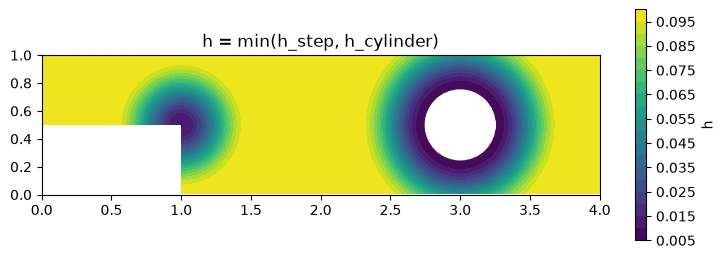

In [15]:
# --- geometry ---------------------------------------------------------------------------
xc, yc, r = 3.0, 0.5, 0.25
if not (p1.x + r < xc < p2.x - r and r < yc < H2 - r):
    raise ValueError("cylinder must sit strictly inside the downstream channel")

centre = Point("c", xc, yc)
cE, cS, cW, cN = (Point(n, xc + dx * r, yc + dy * r)
                  for n, dx, dy in (("cE", 1, 0), ("cS", 0, -1), ("cW", -1, 0), ("cN", 0, 1)))
# Clockwise: E -> S -> W -> N -> E, so the fluid is on the left of every arc.
cylinder = CurveLoop([Arc(a, b, centre, "cylinder", clockwise=True)
                      for a, b in ((cE, cS), (cS, cW), (cW, cN), (cN, cE))], hole=True)
domain_cyl = (loop, cylinder)          # one surface: outer boundary + hole

exact_area_cyl = loop.signed_area() + cylinder.signed_area()
print(f"hole signed area {cylinder.signed_area():+.6f}  (expected -pi r^2 = {-np.pi * r ** 2:+.6f})")
print(f"fluid area {exact_area_cyl:.6f}  (expected L1 H1 + L2 H2 - pi r^2 = {exact_area - np.pi * r ** 2:.6f})")

# --- size field ---------------------------------------------------------------------------
h_cyl = make_size_field(lambda x, y: np.abs(np.hypot(x - xc, y - yc) - r),   # distance to the rim
                        hmin=0.005, hmax=0.1, dmin=0.0, dmax=0.5)
h_both = lambda x, y: np.minimum(h(x, y), h_cyl(x, y))                      # step attractor AND rim attractor
print(f"max growth rate of h_cyl: {1.5 * (0.1 - 0.005) / 0.5:.2f}   rim segments at h = 0.005: ~{2 * np.pi * r / 0.005:.0f}")

def in_fluid(xy):
    return loop.contains(xy) & ~cylinder.contains(xy)

H = np.ma.masked_where(~in_fluid(np.c_[X.ravel(), Y.ravel()]).reshape(X.shape), h_both(X, Y))
fig, ax = plt.subplots(figsize=(9, 3))
cs = ax.contourf(X, Y, H, levels=20, cmap="viridis")
fig.colorbar(cs, ax=ax, label="h")
ax.add_patch(plt.Circle((xc, yc), r, fill=False, color="w", lw=1))
ax.set_aspect("equal"); ax.set_title("h = min(h_step, h_cylinder)")
plt.show()

triangles: 11442 triangles + 0 quads = 11442 cells, 316 rim segments, patches {'cylinder': (16938, 316), 'inlet': (17254, 5), 'outlet': (17259, 10), 'wall': (17269, 119)}
  ok  cells closed: max |sum Sf|: 6.939e-18
  ok  div theorem: max |sum Sf.xf - 2V|: 1.076e-15
  ok  min cell area > 0: 6.038e-06
  ok  total area error: 0.000e+00
  ok  boundary closed: |sum Sf|: 1.110e-16
  ok  owner < neighbour: 0.000e+00
  ok  patch inlet length error: 0.000e+00
  ok  patch outlet length error: 0.000e+00
  ok  patch wall length error: 1.776e-15
  ok  patch cylinder length error: 0.000e+00
  geometric error: area 1.29e-05 (6.6e-05 of the cylinder), perimeter 2.59e-05
  h_mesh/h median 0.98 (5-95%: 0.81-1.09)


hybrid: 8906 triangles + 3508 quads = 12414 cells, 316 rim segments, patches {'cylinder': (20134, 316), 'inlet': (20450, 21), 'outlet': (20471, 26), 'wall': (20497, 119)}
  ok  cells closed: max |sum Sf|: 1.041e-17
  ok  div theorem: max |sum Sf.xf - 2V|: 1.256e-15
  ok  min cell area > 0: 1.913e-07
  ok  total area error: 4.441e-16
  ok  boundary closed: |sum Sf|: 5.027e-16
  ok  owner < neighbour: 0.000e+00
  ok  patch inlet length error: 0.000e+00
  ok  patch outlet length error: 0.000e+00
  ok  patch wall length error: 1.776e-15
  ok  patch cylinder length error: 0.000e+00
  geometric error: area 1.29e-05 (6.6e-05 of the cylinder), perimeter 2.59e-05
  cylinder faces owned by a quad: 100%; first-layer height median 0.0010 (5-95%: 0.0010-0.0010), asked 0.001


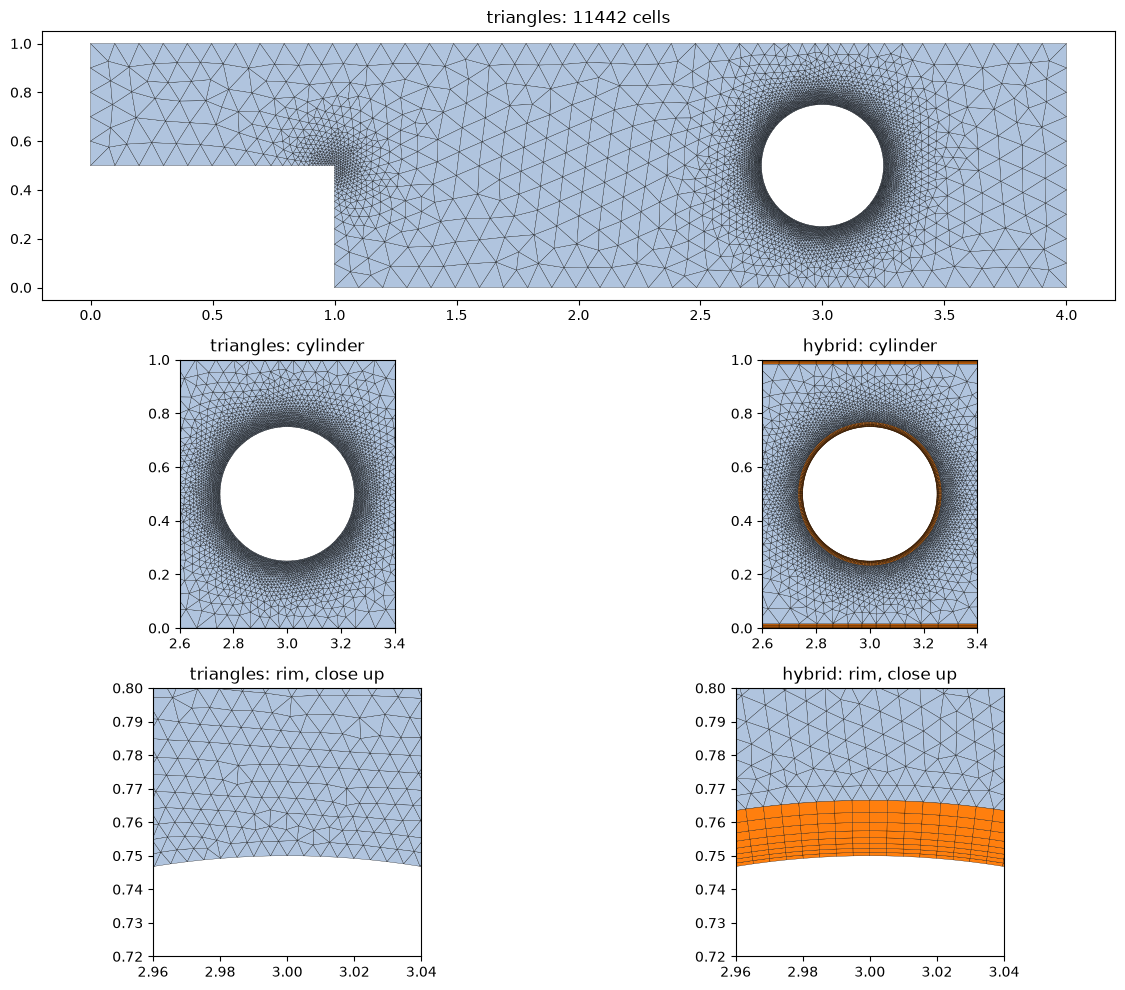

In [16]:
def rim_polygon(fv, patch="cylinder"):
    """Area and perimeter of the polygon the mesh actually uses for the circle (its rim nodes, in order)."""
    s, n = fv.patches[patch]
    xy = fv.points[np.unique(fv.faces[s:s + n])]
    xy = xy[np.argsort(np.arctan2(xy[:, 1] - yc, xy[:, 0] - xc))]          # CCW around the centre
    x, y = xy[:, 0], xy[:, 1]
    area = 0.5 * np.sum(x * np.roll(y, -1) - np.roll(x, -1) * y)
    return area, np.linalg.norm(np.roll(xy, -1, axis=0) - xy, axis=1).sum(), len(xy)


def report_cylinder_mesh(name, fv):
    n_nodes = np.array([len(c) for c in fv.cells])
    rim_area, rim_perim, n_rim = rim_polygon(fv)
    print(f"{name}: {np.sum(n_nodes == 3)} triangles + {np.sum(n_nodes == 4)} quads = {len(n_nodes)} cells, "
          f"{n_rim} rim segments, patches {fv.patches}")
    # Consistency, to round-off: against the boundary the mesh really has (rim polygon, not the circle).
    results = check_fv_mesh(fv, exact_area - rim_area, {**expected_patch_length, "cylinder": rim_perim})
    for k, (val, ok) in results.items():
        print(f"  {'ok ' if ok else 'BAD'} {k}: {val:.3e}")
    assert all(ok for _, ok in results.values()), "an FV mesh check failed"
    # Geometric error: what the chords cut off the true circle. Shrinks like h^2.
    print(f"  geometric error: area {np.pi * r ** 2 - rim_area:.2e} ({(np.pi * r ** 2 - rim_area) / (np.pi * r ** 2):.1e} of the cylinder), "
          f"perimeter {2 * np.pi * r - rim_perim:.2e}")
    return n_nodes


def plot_cells(ax, fv, n_nodes, title):
    colour = np.where(n_nodes == 4, "tab:orange", "lightsteelblue")
    ax.add_collection(PolyCollection([fv.points[c] for c in fv.cells], facecolors=colour, edgecolors="k", linewidths=0.2))
    ax.set_aspect("equal"); ax.autoscale_view(); ax.set_title(title)


# --- all triangles ------------------------------------------------------------------------
P_c, cells_c, segs_c, patch_c = mesh_with_gmsh(domain_cyl, h_both)
fv_c = build_fv_mesh(P_c, cells_c, segs_c, patch_c)
n_c = report_cylinder_mesh("triangles", fv_c)
ratio = np.sqrt(4 * fv_c.V / np.sqrt(3)) / h_both(*fv_c.C.T)
print(f"  h_mesh/h median {np.median(ratio):.2f} (5-95%: {np.percentile(ratio, 5):.2f}-{np.percentile(ratio, 95):.2f})")

# --- hybrid: boundary layer on walls AND cylinder -------------------------------------------
BL_CYL = dict(patches=("wall", "cylinder"), Size=0.001, Ratio=1.2, Thickness=0.02, Quads=1)
P_cb, cells_cb, segs_cb, patch_cb = mesh_with_gmsh(domain_cyl, h_both, boundary_layer=BL_CYL)
fv_cb = build_fv_mesh(P_cb, cells_cb, segs_cb, patch_cb)
n_cb = report_cylinder_mesh("hybrid", fv_cb)
s, n = fv_cb.patches["cylinder"]
nhat = fv_cb.Sf[s:s + n] / np.linalg.norm(fv_cb.Sf[s:s + n], axis=1, keepdims=True)
first = 2 * ((fv_cb.Cf[s:s + n] - fv_cb.C[fv_cb.owner[s:s + n]]) * nhat).sum(axis=1)
print(f"  cylinder faces owned by a quad: {np.mean(n_cb[fv_cb.owner[s:s + n]] == 4):.0%}; first-layer height "
      f"median {np.median(first):.4f} (5-95%: {np.percentile(first, 5):.4f}-{np.percentile(first, 95):.4f}), asked {BL_CYL['Size']}")

# --- pictures -------------------------------------------------------------------------------
fig = plt.figure(figsize=(12, 10))
ax0 = fig.add_subplot(3, 1, 1)
plot_cells(ax0, fv_c, n_c, f"triangles: {len(n_c)} cells")
for k, (fv, nn, label) in enumerate(((fv_c, n_c, "triangles"), (fv_cb, n_cb, "hybrid"))):
    ax = fig.add_subplot(3, 2, 3 + k)
    plot_cells(ax, fv, nn, f"{label}: cylinder")
    ax.set_xlim(xc - 1.6 * r, xc + 1.6 * r); ax.set_ylim(0, H2)
    ax = fig.add_subplot(3, 2, 5 + k)
    plot_cells(ax, fv, nn, f"{label}: rim, close up")
    ax.set_xlim(xc - 0.04, xc + 0.04); ax.set_ylim(yc + r - 0.03, yc + r + 0.05)
plt.tight_layout(); plt.show()

moving forward:
- create gmsh from cad models (freecad, salove, openCascade)

- implement solver/ use openFoam  to start the feedback loop. 